<a href="https://colab.research.google.com/github/Geethika1205/A-4/blob/master/Assignment6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q xgboost dice-ml scikit-learn pandas numpy matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report

from xgboost import XGBClassifier
import dice_ml
from dice_ml import Dice

In [3]:
from sklearn.datasets import fetch_openml

data = fetch_openml(
    name="credit-g",
    version=1,
    as_frame=True
)

df = data.frame.copy()

print(df.head())
print(df.shape)
print(df.columns)

  checking_status  duration                  credit_history  \
0              <0         6  critical/other existing credit   
1        0<=X<200        48                   existing paid   
2     no checking        12  critical/other existing credit   
3              <0        42                   existing paid   
4              <0        24              delayed previously   

               purpose  credit_amount    savings_status employment  \
0             radio/tv           1169  no known savings        >=7   
1             radio/tv           5951              <100     1<=X<4   
2            education           2096              <100     4<=X<7   
3  furniture/equipment           7882              <100     4<=X<7   
4              new car           4870              <100     1<=X<4   

   installment_commitment     personal_status other_parties  ...  \
0                       4         male single          none  ...   
1                       2  female div/dep/mar          none  ...

In [4]:
target = "class"

# Convert target into binary values
df[target] = df[target].map({
    "good": 1,
    "bad": 0
})

X = df.drop(columns=[target])
y = df[target]

print("Features:", X.shape)
print("Target distribution:")
print(y.value_counts())

Features: (1000, 20)
Target distribution:
class
1    700
0    300
Name: count, dtype: int64


In [5]:
continuous_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Continuous Features:")
print(continuous_features)

print("\nCategorical Features:")
print(categorical_features)

Continuous Features:
['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Categorical Features:
['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training size:", X_train.shape)
print("Testing size:", X_test.shape)

Training size: (800, 20)
Testing size: (200, 20)


In [7]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, continuous_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [8]:
import json

# Fit the preprocessor on training data
preprocessor.fit(X_train)

encoder = preprocessor.named_transformers_["cat"].named_steps["onehot"]

encoding_mapping = {}

for feature, categories in zip(
    categorical_features,
    encoder.categories_
):
    encoding_mapping[feature] = categories.tolist()

print("Encoding Mapping:")
print(encoding_mapping)

with open("encoding_mapping.json", "w") as f:
    json.dump(encoding_mapping, f, indent=4)

print("Encoding mapping saved successfully.")

Encoding Mapping:
{'checking_status': ['0<=X<200', '<0', '>=200', 'no checking'], 'credit_history': ['all paid', 'critical/other existing credit', 'delayed previously', 'existing paid', 'no credits/all paid'], 'purpose': ['business', 'domestic appliance', 'education', 'furniture/equipment', 'new car', 'other', 'radio/tv', 'repairs', 'retraining', 'used car'], 'savings_status': ['100<=X<500', '500<=X<1000', '<100', '>=1000', 'no known savings'], 'employment': ['1<=X<4', '4<=X<7', '<1', '>=7', 'unemployed'], 'personal_status': ['female div/dep/mar', 'male div/sep', 'male mar/wid', 'male single'], 'other_parties': ['co applicant', 'guarantor', 'none'], 'property_magnitude': ['car', 'life insurance', 'no known property', 'real estate'], 'other_payment_plans': ['bank', 'none', 'stores'], 'housing': ['for free', 'own', 'rent'], 'job': ['high qualif/self emp/mgmt', 'skilled', 'unemp/unskilled non res', 'unskilled resident'], 'own_telephone': ['none', 'yes'], 'foreign_worker': ['no', 'yes']}
E

In [9]:
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", xgb_model)
])

model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [10]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.74

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.48      0.53        60
           1       0.79      0.85      0.82       140

    accuracy                           0.74       200
   macro avg       0.69      0.67      0.67       200
weighted avg       0.73      0.74      0.73       200



In [11]:
probabilities = model.predict_proba(X_test)

print("Probability predictions:")
print(probabilities[:5])

print("predict_proba is working!")

Probability predictions:
[[0.12666553 0.87333447]
 [0.7871666  0.21283342]
 [0.48981297 0.51018703]
 [0.09013891 0.9098611 ]
 [0.2936964  0.7063036 ]]
predict_proba is working!


In [12]:
import joblib

joblib.dump(model, "xgboost_credit_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [13]:
dice_df = X_train.copy()

dice_df[target] = y_train.values

dice_data = dice_ml.Data(
    dataframe=dice_df,
    continuous_features=continuous_features,
    categorical_features=categorical_features,
    outcome_name=target
)

print("DiCE Data initialized successfully!")

DiCE Data initialized successfully!


In [14]:
explainer = Dice(
    dice_data,
    dice_model,
    method="random"
)

print("DiCE explainer initialized successfully!")

NameError: name 'dice_model' is not defined

In [15]:
import dice_ml
from dice_ml import Dice

dice_model = dice_ml.Model(
    model=model,
    backend="sklearn",
    model_type="classifier"
)

print("DiCE model initialized successfully!")

DiCE model initialized successfully!


In [16]:
explainer = Dice(
    dice_data,
    dice_model,
    method="random"
)

print("DiCE explainer initialized successfully!")

DiCE explainer initialized successfully!


In [17]:
print("Model exists:", 'model' in globals())
print("DiCE data exists:", 'dice_data' in globals())
print("DiCE model exists:", 'dice_model' in globals())
print("Explainer exists:", 'explainer' in globals())

Model exists: True
DiCE data exists: True
DiCE model exists: True
Explainer exists: True


In [19]:
# Select 3 original instances from test dataset
query_instances = X_test.iloc[:3].copy()

print("Selected original instances:")
display(query_instances)

print("Number of instances:", len(query_instances))

Selected original instances:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
977,0<=X<200,18,delayed previously,business,2427,no known savings,>=7,4,male single,none,2,life insurance,42,none,own,2,skilled,1,none,yes
735,0<=X<200,36,all paid,domestic appliance,3990,no known savings,<1,3,female div/dep/mar,none,2,no known property,29,bank,own,1,unemp/unskilled non res,1,none,yes
615,0<=X<200,48,no credits/all paid,business,12204,no known savings,1<=X<4,2,male single,none,2,car,48,bank,own,1,high qualif/self emp/mgmt,1,yes,yes


Number of instances: 3


In [20]:
original_predictions = model.predict(query_instances)

for i, pred in enumerate(original_predictions):
    label = "Good Credit" if pred == 1 else "Bad Credit"
    print(f"Instance {i+1}: {label}")

Instance 1: Good Credit
Instance 2: Bad Credit
Instance 3: Good Credit


In [22]:
# Features that cannot be changed
immutable_features = [
    "age",
    "personal_status"
]

# Features that DiCE is allowed to change
actionable_features = [
    col for col in X.columns
    if col not in immutable_features
]

print("Immutable Features:")
print(immutable_features)

print("\nActionable Features:")
print(actionable_features)

Immutable Features:
['age', 'personal_status']

Actionable Features:
['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status', 'employment', 'installment_commitment', 'other_parties', 'residence_since', 'property_magnitude', 'other_payment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'own_telephone', 'foreign_worker']


In [23]:
print("Actionable features exist:",
      len(actionable_features) > 0)

print("All features valid:",
      all(f in X.columns for f in actionable_features))

Actionable features exist: True
All features valid: True


In [24]:
all_counterfactuals = {}

for i in range(len(query_instances)):

    query_instance = query_instances.iloc[[i]]

    print(f"\nCounterfactuals for Instance {i+1}")

    dice_exp = explainer.generate_counterfactuals(
        query_instance,
        total_CFs=3,
        desired_class="opposite",
        features_to_vary=actionable_features
    )

    cf_df = dice_exp.cf_examples_list[0].final_cfs_df

    all_counterfactuals[i+1] = cf_df

    display(cf_df)


Counterfactuals for Instance 1


100%|██████████| 1/1 [00:00<00:00,  2.78it/s]


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,0<=X<200,18,delayed previously,business,9115,<100,>=7,4,male single,none,...,life insurance,42,none,own,2,skilled,1,none,yes,0
1,0<=X<200,18,delayed previously,business,12000,100<=X<500,>=7,4,male single,none,...,life insurance,42,none,own,2,skilled,1,none,yes,0
2,0<=X<200,66,delayed previously,business,2427,>=1000,>=7,4,male single,none,...,life insurance,42,none,own,2,skilled,1,none,yes,0



Counterfactuals for Instance 2


100%|██████████| 1/1 [00:00<00:00,  2.71it/s]


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,0<=X<200,36,critical/other existing credit,domestic appliance,3990,no known savings,<1,3,female div/dep/mar,none,...,no known property,29,bank,own,1,unemp/unskilled non res,1,none,yes,1
1,0<=X<200,36,delayed previously,domestic appliance,3990,no known savings,unemployed,3,female div/dep/mar,none,...,no known property,29,bank,own,1,unemp/unskilled non res,1,none,yes,1
2,0<=X<200,32,all paid,domestic appliance,3990,no known savings,<1,2,female div/dep/mar,none,...,no known property,29,bank,own,1,unemp/unskilled non res,1,none,yes,1



Counterfactuals for Instance 3


100%|██████████| 1/1 [00:00<00:00,  2.02it/s]


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,0<=X<200,48,no credits/all paid,business,14766,no known savings,1<=X<4,2,male single,none,...,car,48,stores,own,1,high qualif/self emp/mgmt,1,yes,yes,0
1,0<=X<200,48,no credits/all paid,business,12204,<100,1<=X<4,2,male single,none,...,car,48,none,own,1,high qualif/self emp/mgmt,1,yes,yes,0
2,0<=X<200,48,no credits/all paid,business,12204,no known savings,1<=X<4,3,male single,none,...,car,48,stores,own,1,high qualif/self emp/mgmt,1,yes,yes,0


In [25]:
# Features that must not change
immutable_features = [
    "age",
    "personal_status"
]

# All other features are actionable
actionable_features = [
    col for col in X.columns
    if col not in immutable_features
]

print("Immutable features:", immutable_features)
print("Actionable features:", actionable_features)

Immutable features: ['age', 'personal_status']
Actionable features: ['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status', 'employment', 'installment_commitment', 'other_parties', 'residence_since', 'property_magnitude', 'other_payment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'own_telephone', 'foreign_worker']


In [26]:
query_instances = X_test.iloc[:3].copy()

print("Original Instances:")
display(query_instances)

print("Number of instances:", len(query_instances))

Original Instances:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
977,0<=X<200,18,delayed previously,business,2427,no known savings,>=7,4,male single,none,2,life insurance,42,none,own,2,skilled,1,none,yes
735,0<=X<200,36,all paid,domestic appliance,3990,no known savings,<1,3,female div/dep/mar,none,2,no known property,29,bank,own,1,unemp/unskilled non res,1,none,yes
615,0<=X<200,48,no credits/all paid,business,12204,no known savings,1<=X<4,2,male single,none,2,car,48,bank,own,1,high qualif/self emp/mgmt,1,yes,yes


Number of instances: 3


In [27]:
all_counterfactuals = {}

for i in range(len(query_instances)):

    query_instance = query_instances.iloc[[i]]

    print(f"\nGenerating Counterfactuals for Instance {i+1}")

    dice_exp = explainer.generate_counterfactuals(
        query_instance,
        total_CFs=3,
        desired_class="opposite",
        features_to_vary=actionable_features
    )

    cf_df = dice_exp.cf_examples_list[0].final_cfs_df

    all_counterfactuals[i+1] = cf_df

    print("Generated Counterfactuals:")

    if cf_df is not None:
        display(cf_df)
    else:
        print("No counterfactuals generated.")


Generating Counterfactuals for Instance 1


100%|██████████| 1/1 [00:00<00:00,  4.31it/s]

Generated Counterfactuals:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,18,delayed previously,business,17328,no known savings,>=7,4,male single,none,...,life insurance,42,none,own,2,skilled,1,none,yes,0
1,0<=X<200,24,delayed previously,business,2427,<100,>=7,4,male single,none,...,life insurance,42,none,own,2,skilled,1,none,yes,0
2,0<=X<200,52,delayed previously,business,2427,500<=X<1000,>=7,4,male single,none,...,life insurance,42,none,own,2,skilled,1,none,yes,0



Generating Counterfactuals for Instance 2


100%|██████████| 1/1 [00:00<00:00,  2.45it/s]

... (2 outputs left out)


Generating Counterfactuals for Instance 3


100%|██████████| 1/1 [00:00<00:00,  3.54it/s]

Generated Counterfactuals:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,0<=X<200,48,no credits/all paid,business,12204,no known savings,1<=X<4,2,male single,none,...,life insurance,48,bank,own,1,unemp/unskilled non res,1,yes,yes,0
1,0<=X<200,48,no credits/all paid,business,12204,<100,1<=X<4,2,male single,none,...,car,48,bank,own,1,high qualif/self emp/mgmt,1,yes,yes,0
2,0<=X<200,30,no credits/all paid,business,12204,100<=X<500,1<=X<4,2,male single,none,...,car,48,bank,own,1,high qualif/self emp/mgmt,1,yes,yes,0


In [28]:
for instance_id, cf_df in all_counterfactuals.items():

    original = query_instances.iloc[
        instance_id - 1
    ].to_frame().T

    original_prediction = model.predict(original)[0]

    print(f"\nInstance {instance_id}")

    print("Original Prediction:", original_prediction)

    if cf_df is not None and not cf_df.empty:

        for index, row in cf_df.iterrows():

            cf = row[X.columns].to_frame().T

            cf_prediction = model.predict(cf)[0]

            print(
                f"Counterfactual {index+1}:",
                cf_prediction,
                "| Prediction Changed:",
                cf_prediction != original_prediction
            )


Instance 1
Original Prediction: 1
Counterfactual 1: 0 | Prediction Changed: True
Counterfactual 2: 0 | Prediction Changed: True
Counterfactual 3: 0 | Prediction Changed: True

Instance 2
Original Prediction: 0
Counterfactual 1: 1 | Prediction Changed: True
Counterfactual 2: 1 | Prediction Changed: True
Counterfactual 3: 1 | Prediction Changed: True

Instance 3
Original Prediction: 1
Counterfactual 1: 0 | Prediction Changed: True
Counterfactual 2: 0 | Prediction Changed: True
Counterfactual 3: 0 | Prediction Changed: True


In [29]:
filtered_counterfactuals = {}

for instance_id, cf_df in all_counterfactuals.items():

    original = query_instances.iloc[
        instance_id - 1
    ]

    original_prediction = model.predict(
        original.to_frame().T
    )[0]

    valid_rows = []

    if cf_df is not None and not cf_df.empty:

        for _, row in cf_df.iterrows():

            cf = row[X.columns]

            # Check immutable features
            immutable_valid = all(
                original[f] == cf[f]
                for f in immutable_features
            )

            # Check whether prediction flips
            cf_prediction = model.predict(
                cf.to_frame().T
            )[0]

            prediction_changed = (
                cf_prediction != original_prediction
            )

            if immutable_valid and prediction_changed:
                valid_rows.append(row)

    filtered_counterfactuals[instance_id] = pd.DataFrame(
        valid_rows,
        columns=cf_df.columns if cf_df is not None else X.columns
    )

    print(
        f"Instance {instance_id}: "
        f"{len(valid_rows)} valid counterfactuals"
    )

Instance 1: 3 valid counterfactuals
Instance 2: 3 valid counterfactuals
Instance 3: 3 valid counterfactuals


In [30]:
from scipy.sparse import issparse

def calculate_l1(original, counterfactual):

    preprocessor = model.named_steps["preprocessor"]

    original_encoded = preprocessor.transform(
        original[X.columns]
    )

    cf_encoded = preprocessor.transform(
        counterfactual[X.columns]
    )

    if issparse(original_encoded):
        original_encoded = original_encoded.toarray()

    if issparse(cf_encoded):
        cf_encoded = cf_encoded.toarray()

    distance = np.abs(
        original_encoded - cf_encoded
    ).sum()

    return float(distance)

print("L1 distance function created successfully!")

L1 distance function created successfully!


In [31]:
def get_feature_changes(original, counterfactual):

    changes = []

    for feature in actionable_features:

        old_value = original[feature]
        new_value = counterfactual[feature]

        if old_value != new_value:

            if feature in continuous_features:

                magnitude = abs(
                    float(new_value) - float(old_value)
                )

            else:
                magnitude = "Categorical change"

            changes.append({
                "Feature": feature,
                "Original Value": old_value,
                "New Value": new_value,
                "Magnitude": magnitude
            })

    return changes

In [32]:
results = []

for instance_id, cf_df in filtered_counterfactuals.items():

    original = query_instances.iloc[
        instance_id - 1
    ]

    original_df = original.to_frame().T

    original_prediction = int(
        model.predict(original_df)[0]
    )

    original_label = (
        "Good Credit"
        if original_prediction == 1
        else "Bad Credit"
    )

    for cf_number, (_, cf_row) in enumerate(
        cf_df.iterrows(), start=1
    ):

        counterfactual = cf_row[X.columns].to_frame().T

        cf_prediction = int(
            model.predict(counterfactual)[0]
        )

        cf_label = (
            "Good Credit"
            if cf_prediction == 1
            else "Bad Credit"
        )

        changes = get_feature_changes(
            original,
            counterfactual.iloc[0]
        )

        l1_distance = calculate_l1(
            original_df,
            counterfactual
        )

        results.append({

            "Instance": instance_id,
            "Counterfactual": cf_number,
            "Original Prediction": original_label,
            "Counterfactual Prediction": cf_label,
            "Changed Features": changes,
            "L1 Distance": l1_distance

        })

results_df = pd.DataFrame(results)

pd.set_option("display.max_colwidth", None)

display(results_df)

,Instance,Counterfactual,Original Prediction,Counterfactual Prediction,Changed Features,L1 Distance
0,1,1,Good Credit,Bad Credit,"[{'Feature': 'checking_status', 'Original Value': '0<=X<200', 'New Value': '<0', 'Magnitude': 'Categorical change'}, {'Feature': 'credit_amount', 'Original Value': 2427, 'New Value': 17328, 'Magnitude': 14901.0}]",14903.0
1,1,2,Good Credit,Bad Credit,"[{'Feature': 'duration', 'Original Value': 18, 'New Value': 24, 'Magnitude': 6.0}, {'Feature': 'savings_status', 'Original Value': 'no known savings', 'New Value': '<100', 'Magnitude': 'Categorical change'}]",8.0
2,1,3,Good Credit,Bad Credit,"[{'Feature': 'duration', 'Original Value': 18, 'New Value': 52, 'Magnitude': 34.0}, {'Feature': 'savings_status', 'Original Value': 'no known savings', 'New Value': '500<=X<1000', 'Magnitude': 'Categorical change'}]",36.0
3,2,1,Bad Credit,Good Credit,"[{'Feature': 'credit_amount', 'Original Value': 3990, 'New Value': 2831, 'Magnitude': 1159.0}, {'Feature': 'employment', 'Original Value': '<1', 'New Value': '4<=X<7', 'Magnitude': 'Categorical change'}]",1161.0
4,2,2,Bad Credit,Good Credit,"[{'Feature': 'credit_history', 'Original Value': 'all paid', 'New Value': 'critical/other existing credit', 'Magnitude': 'Categorical change'}, {'Feature': 'foreign_worker', 'Original Value': 'yes', 'New Value': 'no', 'Magnitude': 'Categorical change'}]",4.0
5,2,3,Bad Credit,Good Credit,"[{'Feature': 'employment', 'Original Value': '<1', 'New Value': 'unemployed', 'Magnitude': 'Categorical change'}, {'Feature': 'housing', 'Original Value': 'own', 'New Value': 'for free', 'Magnitude': 'Categorical change'}]",4.0
6,3,1,Good Credit,Bad Credit,"[{'Feature': 'property_magnitude', 'Original Value': 'car', 'New Value': 'life insurance', 'Magnitude': 'Categorical change'}, {'Feature': 'job', 'Original Value': 'high qualif/self emp/mgmt', 'New Value': 'unemp/unskilled non res', 'Magnitude': 'Categorical change'}]",4.0
7,3,2,Good Credit,Bad Credit,"[{'Feature': 'savings_status', 'Original Value': 'no known savings', 'New Value': '<100', 'Magnitude': 'Categorical change'}, {'Feature': 'residence_since', 'Original Value': 2, 'New Value': 3, 'Magnitude': 1.0}]",3.0
8,3,3,Good Credit,Bad Credit,"[{'Feature': 'duration', 'Original Value': 48, 'New Value': 30, 'Magnitude': 18.0}, {'Feature': 'savings_status', 'Original Value': 'no known savings', 'New Value': '100<=X<500', 'Magnitude': 'Categorical change'}]",20.0


In [33]:
for instance_id, cf_df in filtered_counterfactuals.items():

    print(f"\nInstance {instance_id} Results")

    if cf_df.empty:
        print("No valid counterfactuals found.")
    else:
        display(cf_df[X.columns])


Instance 1 Results


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,18,delayed previously,business,17328,no known savings,>=7,4,male single,none,2,life insurance,42,none,own,2,skilled,1,none,yes
1,0<=X<200,24,delayed previously,business,2427,<100,>=7,4,male single,none,2,life insurance,42,none,own,2,skilled,1,none,yes
2,0<=X<200,52,delayed previously,business,2427,500<=X<1000,>=7,4,male single,none,2,life insurance,42,none,own,2,skilled,1,none,yes



Instance 2 Results


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,0<=X<200,36,all paid,domestic appliance,2831,no known savings,4<=X<7,3,female div/dep/mar,none,2,no known property,29,bank,own,1,unemp/unskilled non res,1,none,yes
1,0<=X<200,36,critical/other existing credit,domestic appliance,3990,no known savings,<1,3,female div/dep/mar,none,2,no known property,29,bank,own,1,unemp/unskilled non res,1,none,no
2,0<=X<200,36,all paid,domestic appliance,3990,no known savings,unemployed,3,female div/dep/mar,none,2,no known property,29,bank,for free,1,unemp/unskilled non res,1,none,yes



Instance 3 Results


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,0<=X<200,48,no credits/all paid,business,12204,no known savings,1<=X<4,2,male single,none,2,life insurance,48,bank,own,1,unemp/unskilled non res,1,yes,yes
1,0<=X<200,48,no credits/all paid,business,12204,<100,1<=X<4,2,male single,none,3,car,48,bank,own,1,high qualif/self emp/mgmt,1,yes,yes
2,0<=X<200,30,no credits/all paid,business,12204,100<=X<500,1<=X<4,2,male single,none,2,car,48,bank,own,1,high qualif/self emp/mgmt,1,yes,yes


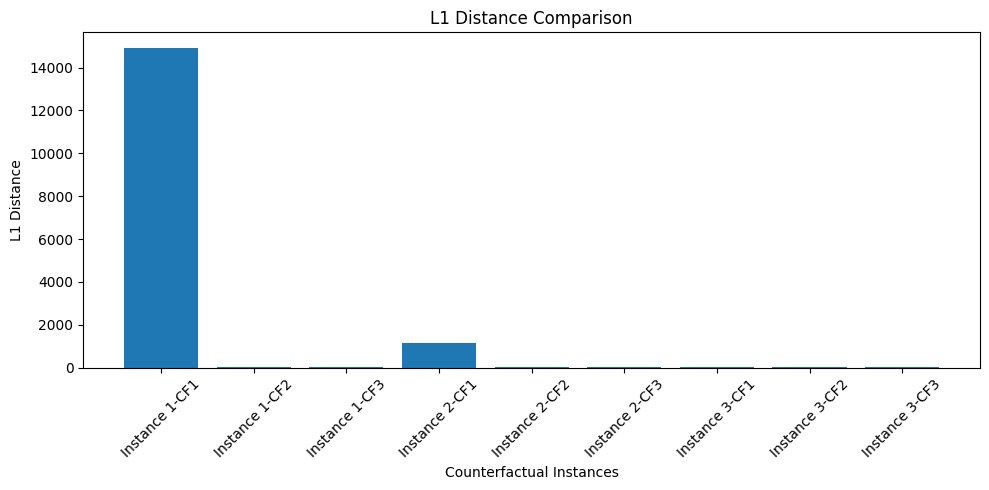

In [34]:
if not results_df.empty:

    plt.figure(figsize=(10, 5))

    labels = [
        f"Instance {row['Instance']}-CF{row['Counterfactual']}"
        for _, row in results_df.iterrows()
    ]

    plt.bar(
        labels,
        results_df["L1 Distance"]
    )

    plt.xlabel("Counterfactual Instances")
    plt.ylabel("L1 Distance")
    plt.title("L1 Distance Comparison")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    print("No valid counterfactuals available for visualization.")

In [35]:
import json

# Save combined results
results_df.to_csv(
    "counterfactual_results.csv",
    index=False
)

# Save separate tables
for instance_id, cf_df in filtered_counterfactuals.items():

    cf_df.to_csv(
        f"instance_{instance_id}_counterfactuals.csv",
        index=False
    )

print("All counterfactual tables saved successfully!")

All counterfactual tables saved successfully!


In [36]:
with open("encoding_mapping.json", "w") as f:

    json.dump(
        encoding_mapping,
        f,
        indent=4
    )

print("Encoding mapping saved!")

Encoding mapping saved!


In [37]:
total_generated = sum(
    0 if cf is None else len(cf)
    for cf in all_counterfactuals.values()
)

total_valid = sum(
    len(cf)
    for cf in filtered_counterfactuals.values()
)

report = f"""
ACTIONABLE COUNTERFACTUAL EXPLANATION REPORT

1. OBJECTIVE
Train an XGBoost classifier and generate actionable
counterfactual explanations using DiCE.

2. DATASET
German Credit Dataset from OpenML.

3. MACHINE LEARNING MODEL
XGBoost Classifier.

4. PREPROCESSING
Numerical features were imputed using median imputation.
Categorical features were imputed using most frequent
imputation and encoded using OneHotEncoder.

5. COUNTERFACTUAL GENERATION
DiCE was used to generate up to three counterfactuals
for each of three original test instances.

6. IMMUTABLE FEATURES
{immutable_features}

7. ACTIONABLE FEATURES
{actionable_features}

8. COUNTERFACTUAL RESULTS
Total generated: {total_generated}
Total valid after filtering: {total_valid}

9. ACTIONABILITY
Counterfactuals that changed immutable features or failed
to flip the prediction were removed.

10. DISTANCE METRIC
L1 distance was calculated using the transformed
OneHotEncoder feature representation.

11. FEASIBILITY
Changes to numerical features such as credit amount and
duration may be possible subject to financial constraints.
Categorical changes require individual feasibility checks.
The model's suggested changes do not guarantee actual
credit approval.

12. CONCLUSION
The implemented system demonstrates how XGBoost and
DiCE can identify alternative feature combinations
that change model predictions while preserving
specified immutable features.
"""

with open("counterfactual_report.txt", "w") as f:
    f.write(report)

print(report)


ACTIONABLE COUNTERFACTUAL EXPLANATION REPORT

1. OBJECTIVE
Train an XGBoost classifier and generate actionable
counterfactual explanations using DiCE.

2. DATASET
German Credit Dataset from OpenML.

3. MACHINE LEARNING MODEL
XGBoost Classifier.

4. PREPROCESSING
Numerical features were imputed using median imputation.
Categorical features were imputed using most frequent
imputation and encoded using OneHotEncoder.

5. COUNTERFACTUAL GENERATION
DiCE was used to generate up to three counterfactuals
for each of three original test instances.

6. IMMUTABLE FEATURES
['age', 'personal_status']

7. ACTIONABLE FEATURES
['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status', 'employment', 'installment_commitment', 'other_parties', 'residence_since', 'property_magnitude', 'other_payment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'own_telephone', 'foreign_worker']

8. COUNTERFACTUAL RESULTS
Total generated: 9
Total valid after filterin

In [38]:
from google.colab import files

files.download("counterfactual_results.csv")
files.download("encoding_mapping.json")
files.download("counterfactual_report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
for instance_id in filtered_counterfactuals:

    files.download(
        f"instance_{instance_id}_counterfactuals.csv"
    )

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>